---
title: Estimation and Prediction in AR models
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

## Dataset One: GDP

The following data is on US GDP from FRED (https://fred.stlouisfed.org/series/GDP). It measures the market value of the goods and services produced by labor and property located in the United States. It is in the units of billions of dollars (with seasonal adjustment but no adjustment for inflation). Compiled by the Bureau of Economic Analysis (BEA), GDP is a broad measure of U.S. economic output and is used to track overall economic activity.

  observation_date      GDP
0       1947-01-01  243.164
1       1947-04-01  245.968
2       1947-07-01  249.585
3       1947-10-01  259.745
4       1948-01-01  265.742


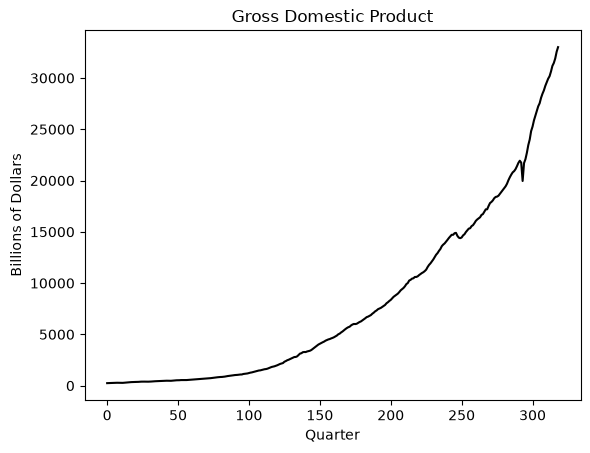

In [2]:
gdp = pd.read_csv("GDP_29Oct2026.csv")
print(gdp.head())
y = gdp['GDP'].to_numpy()
plt.plot(y, color = 'black')
plt.xlabel('Quarter')
plt.ylabel('Billions of Dollars')
plt.title('Gross Domestic Product')
plt.show()

We will fit AR(p) models to this dataset, and use the fitted models to predict future values. Let us leave the last 50 observations (corresponding to 12.5 years; note that this is quarterly data) as test values, and the remaining data form the training data. We will fit AR(p) models to the training data, predict the test values and then compare the predictions with the actual test values. 

In [3]:
n = len(y)
tme = range(1, n+1)
n_test = 50
#n_test = 12 
n_train = n - n_test
y_train = y[:n_train]
tme_train = tme[:n_train]
y_test = y[n_train:]
tme_test = tme[n_train:]

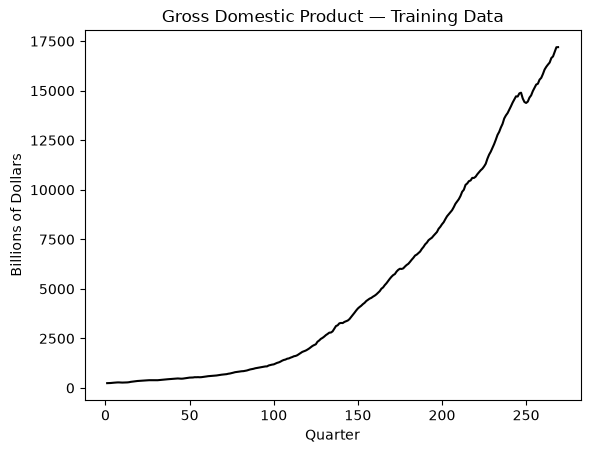

In [4]:
plt.plot(tme_train, y_train, color='black')
plt.xlabel('Quarter')
plt.ylabel('Billions of Dollars')
plt.title('Gross Domestic Product — Training Data')
plt.show()

Below, we fit AR(1) to the training data. There are two ways of doing this. Either manually create $y$ and $X$ and use OLS, or use the AutoReg function from statsmodels. 

In [5]:
p = 1
yreg = y_train[p:] #these are the response values in the autoregression
Xmat = np.ones((n_train-p, 1)) #this will be the design matrix (X) in the autoregression
for j in range(1, p+1):
    col = y_train[p-j : n_train-j].reshape(-1, 1)
    Xmat = np.column_stack([Xmat, col])

armod = sm.OLS(yreg, Xmat).fit()
print(armod.params)
print(armod.summary())

[19.18439505  1.0087699 ]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 2.455e+06
Date:                Fri, 30 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:36:28   Log-Likelihood:                -1447.8
No. Observations:                 268   AIC:                             2900.
Df Residuals:                     266   BIC:                             2907.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         19.1844     

In [6]:
from statsmodels.tsa.ar_model import AutoReg
armod_sm = AutoReg(y_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  269
Model:                     AutoReg(1)   Log Likelihood               -1447.753
Method:               Conditional MLE   S.D. of innovations             53.685
Date:                Fri, 30 Oct 2026   AIC                           2901.507
Time:                        21:36:28   BIC                           2912.279
Sample:                             1   HQIC                          2905.833
                                  269                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         19.1844      4.598      4.172      0.000      10.172      28.197
y.L1           1.0088      0.001   1572.831      0.000       1.008       1.010
                                    Roots           

Here are some observations comparing the above two outputs:  
1. The parameter estimates are exactly the same.
2. The regression summary gives t-scores corresponding to each parameter estimate while the AutoReg summary only gives z-scores
3. The standard errors are slightly different.

The standard errors given by the regression summary correspond to the square roots of the diagonal entries of: 
\begin{equation*}
   \hat{\sigma}^2 (X^T X)^{-1} ~~~ \text{ where } \hat{\sigma}^2 = \sqrt{\frac{\|Y - X \hat{\beta}\|^2}{n-2p-1}}
\end{equation*}
while the standard errors reported by AutoReg summary correspond to the square roots of the diagonal entries of:
\begin{equation*}
   \hat{\sigma}_{\text{MLE}}^2 (X^T X)^{-1} ~~~ \text{ where } \hat{\sigma}_{\text{MLE}}^2 = \sqrt{\frac{\|Y - X \hat{\beta}\|^2}{n-p}}
\end{equation*}

Here is how the fitted model can be used to predict the test observations. 

In [7]:
k = n_test
fcast = armod_sm.get_prediction(start = n_train, end = n_train+k-1)
fcast_mean = fcast.predicted_mean #this gives point predictions for the future values of the time series 

The method that the above function uses to calculate the predictions was detailed in class; and is captured in the code below. 

In [8]:
#Predictions
yhat = np.concatenate([y_train.astype(float), np.full(k, -9999)]) #extend data by k placeholder values
phi_vals = armod_sm.params
for i in range(1, k+1):
    ans = phi_vals[0]
    for j in range(1, p+1):
        ans += phi_vals[j] * yhat[n_train+i-j-1]
    yhat[n_train+i-1] = ans
predvalues = yhat[n_train:]

#Check that both predictions are identical:
print(np.column_stack([predvalues, fcast_mean]))
preds_nolog = fcast_mean

[[17367.744854   17367.744854  ]
 [17539.24265126 17539.24265126]
 [17712.24446723 17712.24446723]
 [17886.76349198 17886.76349198]
 [18062.8130313  18062.8130313 ]
 [18240.40650764 18240.40650764]
 [18419.55746118 18419.55746118]
 [18600.27955083 18600.27955083]
 [18782.58655532 18782.58655532]
 [18966.49237418 18966.49237418]
 [19152.01102885 19152.01102885]
 [19339.15666375 19339.15666375]
 [19527.94354734 19527.94354734]
 [19718.38607319 19718.38607319]
 [19910.49876114 19910.49876114]
 [20104.29625833 20104.29625833]
 [20299.79334038 20299.79334038]
 [20497.00491247 20497.00491247]
 [20695.94601052 20695.94601052]
 [20896.6318023  20896.6318023 ]
 [21099.07758859 21099.07758859]
 [21303.29880438 21303.29880438]
 [21509.31102    21509.31102   ]
 [21717.12994235 21717.12994235]
 [21926.77141607 21926.77141607]
 [22138.25142475 22138.25142475]
 [22351.58609216 22351.58609216]
 [22566.79168347 22566.79168347]
 [22783.8846065  22783.8846065 ]
 [23002.88141297 23002.88141297]
 [23223.79

Below we plot the predictions along with the actual test observations. 

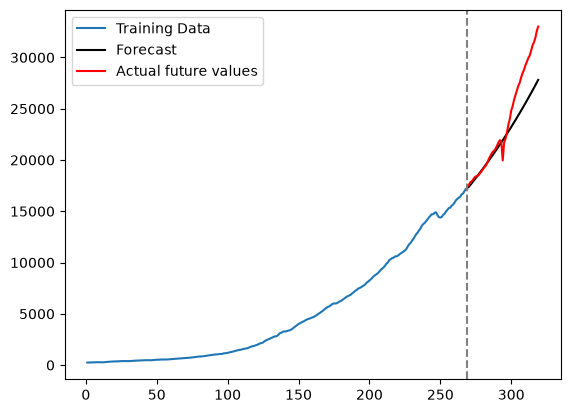

In [9]:
plt.plot(tme_train, y_train, label = 'Training Data')
plt.plot(tme_test, fcast_mean, label = 'Forecast', color = 'black')
plt.plot(tme_test, y_test, color = 'red',  label = 'Actual future values')
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.legend()
plt.show()

Next we discuss prediction uncertainty quantification. The prediction standard errors, and the associated uncertainty intervals, are calculated as follows. 

In [10]:
fcast_se = fcast.se_mean
alpha = 0.05
from scipy import stats
z_alpha_half = stats.norm.ppf(1 - alpha/2)
predlower = predvalues - z_alpha_half * fcast_se
predupper = predvalues + z_alpha_half * fcast_se
fcast_int = fcast.conf_int()
print(np.column_stack([predlower, predupper, fcast_int]))


[[17262.525004   17472.96470399 17262.525004   17472.96470399]
 [17389.78539276 17688.69990976 17389.78539276 17688.69990976]
 [17528.39071614 17896.09821831 17528.39071614 17896.09821831]
 [17673.52910847 18099.99787549 17673.52910847 18099.99787549]
 [17823.35294746 18302.27311514 17823.35294746 18302.27311514]
 [17976.92498864 18503.88802663 17976.92498864 18503.88802663]
 [18133.69608893 18705.41883342 18133.69608893 18705.41883342]
 [18293.31453482 18907.24456685 18293.31453482 18907.24456685]
 [18455.54111949 19109.63199114 18455.54111949 19109.63199114]
 [18620.20608372 19312.77866463 18620.20608372 19312.77866463]
 [18787.1851721  19516.83688561 18787.1851721  19516.83688561]
 [18956.385361   19721.9279665  18956.385361   19721.9279665 ]
 [19127.73587643 19928.15121825 19127.73587643 19928.15121825]
 [19301.18228807 20135.58985832 19301.18228807 20135.58985832]
 [19476.68248368 20344.3150386  19476.68248368 20344.3150386 ]
 [19654.20384085 20554.3886758  19654.20384085 20554.38

Below we plot the predictions along with uncertainty intervals.

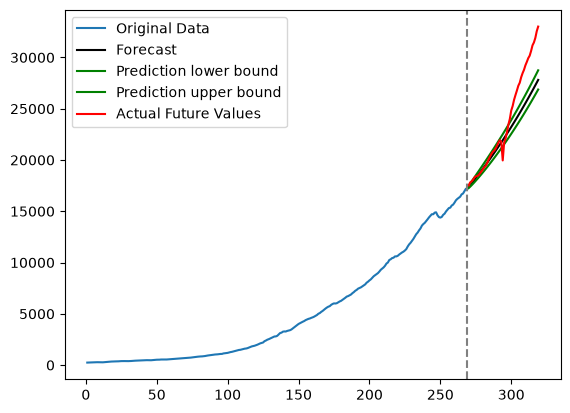

In [11]:
#Plotting predictions along with uncertainty:
plt.plot(tme_train, y_train, label = 'Original Data')
plt.plot(tme_test, predvalues, label = 'Forecast', color = 'black')
plt.plot(tme_test, predlower, color = 'green', label = 'Prediction lower bound')
plt.plot(tme_test, predupper, color = 'green', label = 'Prediction upper bound')
plt.plot(tme_test, y_test, color = 'red', label = 'Actual Future Values')
plt.legend()
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.show()

In this example, the predicted values are somewhat below the actual test values. 

Instead of applying AR models, directly to the raw data, it is common practice to apply them to the logarithms. 

For GDP (and also for the house prices data which we shall look at next), it is often natural to think of fluctuations in percentage terms. A 5% fluctuation is twice as large in dollars when the level of the series doubles, but its size on the log scale is unchanged: multiplying $y_t$ by $1.05$ adds $\log(1.05)$ to $\log y_t$. Taking logarithms can therefore make the residual spread more stable, better matching the constant error variance assumption of an AR model. 

In [13]:
ylog_train = np.log(y_train)
ylog_test = np.log(y_test)

In [14]:
armod_sm = AutoReg(ylog_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  269
Model:                     AutoReg(1)   Log Likelihood                 830.433
Method:               Conditional MLE   S.D. of innovations              0.011
Date:                Fri, 30 Oct 2026   AIC                          -1654.866
Time:                        21:40:23   BIC                          -1644.093
Sample:                             1   HQIC                         -1650.539
                                  269                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0283      0.004      7.232      0.000       0.021       0.036
y.L1           0.9984      0.000   2014.926      0.000       0.997       0.999
                                    Roots           

Predictions are obtained as follows. 

In [15]:
fcast = armod_sm.get_prediction(start = n_train, end = n_train+k-1)
fcast_mean = fcast.predicted_mean #this gives the point predictions

Prediction uncertainty intervals are obtained as follows. 

In [16]:
fcast_se = fcast.se_mean
alpha = 0.05
z_alpha_half = stats.norm.ppf(1 - alpha/2)
predlower = fcast_mean - z_alpha_half * fcast_se
predupper = fcast_mean + z_alpha_half * fcast_se
fcast_int = fcast.conf_int()
print(np.column_stack([predlower, predupper, fcast_int]))

[[ 9.74390031  9.78668836  9.74390031  9.78668836]
 [ 9.74780358  9.80826671  9.74780358  9.80826671]
 [ 9.7537592   9.82775201  9.7537592   9.82775201]
 [ 9.76077004  9.84614143  9.76077004  9.84614143]
 [ 9.76844957  9.8638216   9.76844957  9.8638216 ]
 [ 9.77659938  9.88099097  9.77659938  9.88099097]
 [ 9.78510153  9.89776754  9.78510153  9.89776754]
 [ 9.79387913  9.9142283   9.79387913  9.9142283 ]
 [ 9.80287871  9.93042675  9.80287871  9.93042675]
 [ 9.81206134  9.94640189  9.81206134  9.94640189]
 [ 9.82139761  9.96218321  9.82139761  9.96218321]
 [ 9.83086465  9.97779363  9.83086465  9.97779363]
 [ 9.84044427  9.99325141  9.84044427  9.99325141]
 [ 9.85012171 10.00857138  9.85012171 10.00857138]
 [ 9.85988481 10.02376575  9.85988481 10.02376575]
 [ 9.86972339 10.03884477  9.86972339 10.03884477]
 [ 9.87962885 10.0538171   9.87962885 10.0538171 ]
 [ 9.88959383 10.06869017  9.88959383 10.06869017]
 [ 9.89961198 10.0834704   9.89961198 10.0834704 ]
 [ 9.90967777 10.09816336  9.90

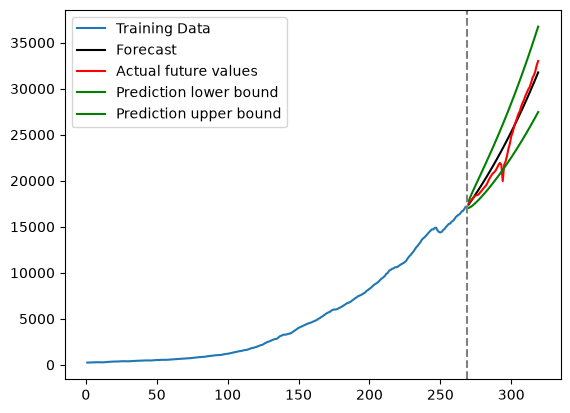

In [17]:
plt.plot(tme_train, y_train, label = 'Training Data')
plt.plot(tme_test, np.exp(fcast_mean), label = 'Forecast', color = 'black') #Note the exponentiation
plt.plot(tme_test, y_test, color = 'red',  label = 'Actual future values')
plt.plot(tme_test, np.exp(predlower), color = 'green', label = 'Prediction lower bound')
plt.plot(tme_test, np.exp(predupper), color = 'green', label = 'Prediction upper bound')
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.legend()
plt.show()

Note that now the predictions are slightly closer to the actual observations. 

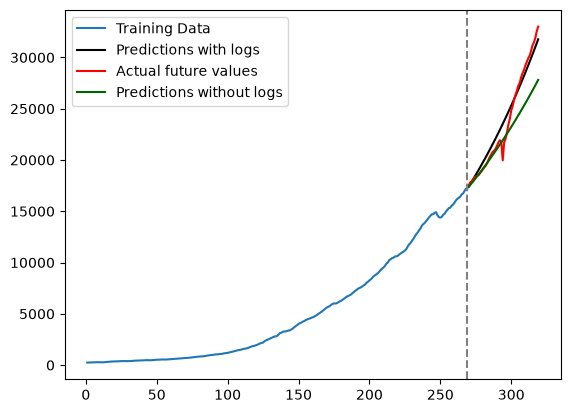

In [18]:
plt.plot(tme_train, y_train, label = 'Training Data')
plt.plot(tme_test, np.exp(fcast_mean), label = 'Predictions with logs', color = 'black') #Note the exponentiation
plt.plot(tme_test, y_test, color = 'red',  label = 'Actual future values')
plt.plot(tme_test, preds_nolog, color = 'darkgreen',  label = 'Predictions without logs')
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.legend()
plt.show()

### Residuals: raw data versus logarithms

Below we plot the residuals from the AR fit for both the models (AR fit to the raw data and AR fit to the logarithms). 

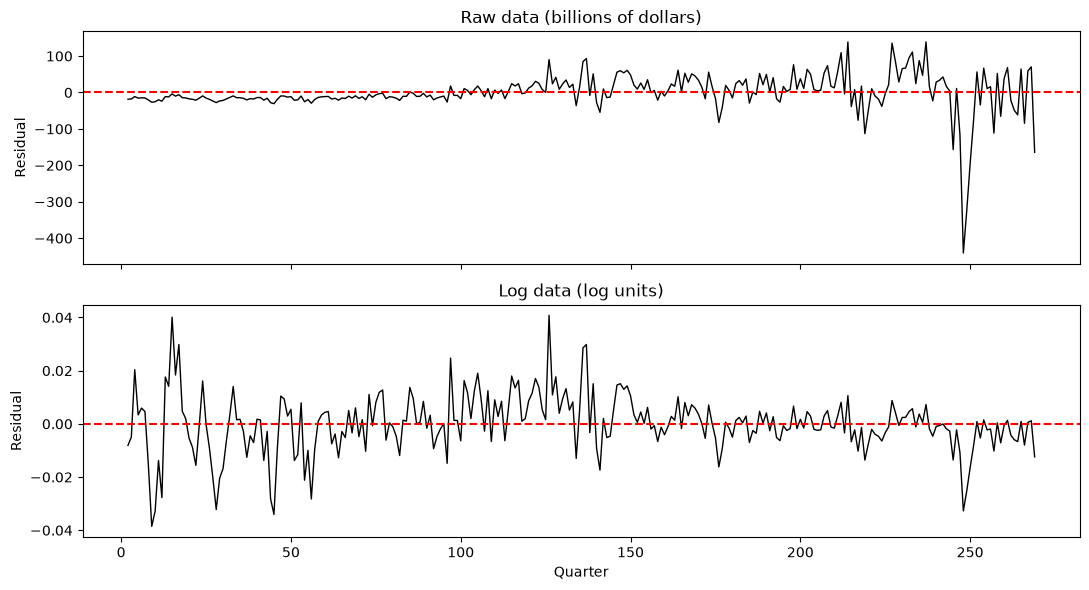

In [21]:
resid_raw = AutoReg(y_train, lags=p).fit().resid
resid_log = armod_sm.resid

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, resid, label in zip(axes, [resid_raw, resid_log],
                           ['Raw data (billions of dollars)', 'Log data (log units)']):
    ax.plot(tme_train[p:], resid, color='black', linewidth=1)
    ax.axhline(0, color='red', linestyle='--')
    ax.set(title=label, ylabel='Residual')
axes[-1].set_xlabel('Quarter')
plt.tight_layout()
plt.show()

The raw residuals become much more variable as spending grows. Taking logarithms substantially reduces this pattern, making the constant error variance assumption more plausible. Compare how the spread changes over time, not the numerical sizes of residuals on these different scales.

## Dataset Two: House Price Data from FRED

Consider the following quarterly dataset (again from FRED: https://fred.stlouisfed.org/series/ASPUS) on average sales price of houses sold for the US. 

  observation_date  ASPUS
0       1963-01-01  19300
1       1963-04-01  19400
2       1963-07-01  19200
3       1963-10-01  19600
4       1964-01-01  19600


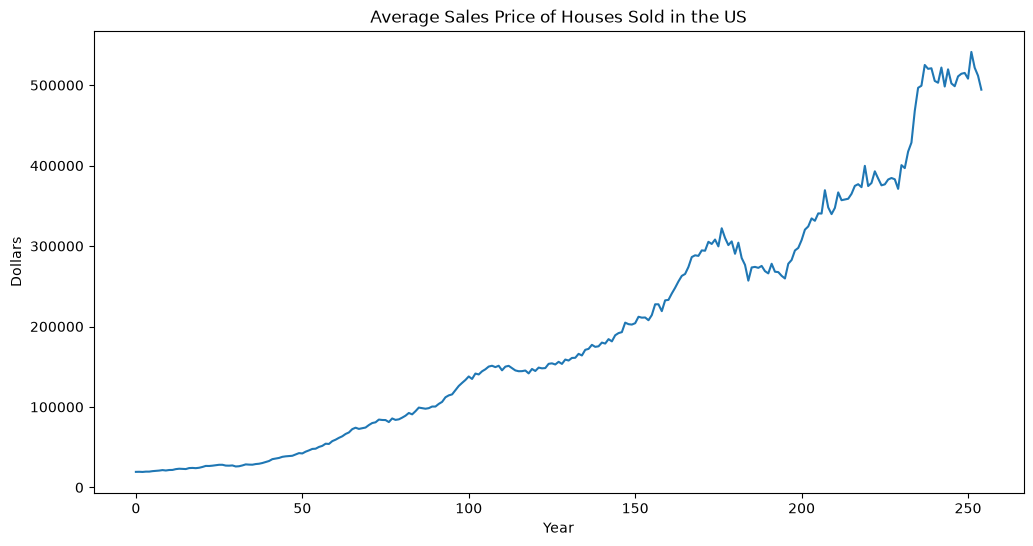

In [24]:
hprice = pd.read_csv('ASPUS_October2026.csv')
print(hprice.head())
y = hprice['ASPUS'].to_numpy()
plt.figure(figsize = (12, 6))
plt.plot(y)
plt.xlabel('Year')
plt.ylabel('Dollars')
plt.title('Average Sales Price of Houses Sold in the US')
plt.show()

Training-test split: 

In [25]:
n = len(y)
tme = range(1, n+1)
#n_test = 50
n_test = 100
n_train = n - n_test
y_train = y[:n_train]
tme_train = tme[:n_train]
y_test = y[n_train:]
tme_test = tme[n_train:]

Below we fit AR(1) to the raw data. 

In [27]:
p = 1
from statsmodels.tsa.ar_model import AutoReg
armod_sm = AutoReg(y_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  155
Model:                     AutoReg(1)   Log Likelihood               -1421.301
Method:               Conditional MLE   S.D. of innovations           2465.844
Date:                Fri, 30 Oct 2026   AIC                           2848.602
Time:                        21:55:35   BIC                           2857.713
Sample:                             1   HQIC                          2852.303
                                  155                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        671.9911    368.218      1.825      0.068     -49.702    1393.684
y.L1           1.0059      0.003    302.244      0.000       0.999       1.012
                                    Roots           

Below we obtain predictions. 

In [29]:
k = n_test
fcast = armod_sm.get_prediction(start = n_train, end = n_train+k-1)
fcast_mean = fcast.predicted_mean #this gives point predictions for the future values of the time series 
preds_nolog = fcast_mean

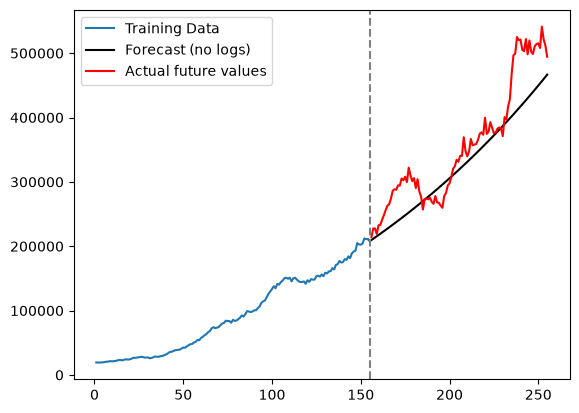

In [30]:
plt.plot(tme_train, y_train, label = 'Training Data')
plt.plot(tme_test, fcast_mean, label = 'Forecast (no logs)', color = 'black')
plt.plot(tme_test, y_test, color = 'red',  label = 'Actual future values')
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.legend()
plt.show()

In [31]:
fcast_se = fcast.se_mean
alpha = 0.05
z_alpha_half = stats.norm.ppf(1 - alpha/2)
predlower = fcast_mean - z_alpha_half * fcast_se
predupper = fcast_mean + z_alpha_half * fcast_se
fcast_int = fcast.conf_int()
print(np.column_stack([predlower, predupper, fcast_int]))

[[204870.58737551 214536.51969315 204870.58737551 214536.51969315]
 [204763.25865112 218473.51896037 204763.25865112 218473.51896037]
 [205123.821886   221965.32346879 205123.821886   221965.32346879]
 [205729.75702797 225234.58778946 205729.75702797 225234.58778946]
 [206495.17430941 228367.3370061  206495.17430941 228367.3370061 ]
 [207376.18106667 231407.59990046 207376.18106667 231407.59990046]
 [208346.80078729 234381.48990978 208346.80078729 234381.48990978]
 [209390.17604703 237306.00219464 209390.17604703 237306.00219464]
 [210494.64798737 240192.93416618 210494.64798737 240192.93416618]
 [211651.76725522 243050.87455129 211651.76725522 243050.87455129]
 [212855.18728792 245886.31011244 212855.18728792 245886.31011244]
 [214100.00424011 248704.28572573 214100.00424011 248704.28572573]
 [215382.34130984 251508.82005967 215382.34130984 251508.82005967]
 [216699.07525994 254303.17905882 216699.07525994 254303.17905882]
 [218047.64988628 257090.06248045 218047.64988628 257090.06248

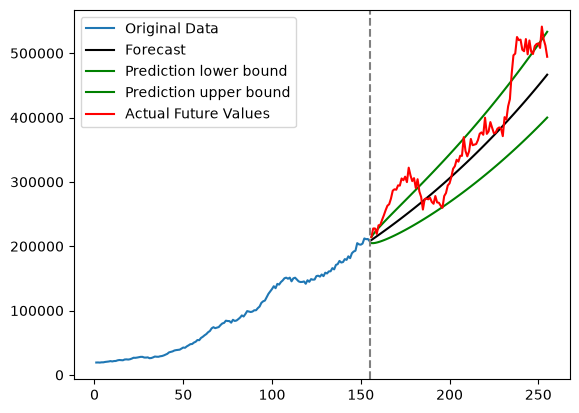

In [32]:
#Plotting predictions along with uncertainty:
plt.plot(tme_train, y_train, label = 'Original Data')
plt.plot(tme_test, fcast_mean, label = 'Forecast', color = 'black')
plt.plot(tme_test, predlower, color = 'green', label = 'Prediction lower bound')
plt.plot(tme_test, predupper, color = 'green', label = 'Prediction upper bound')
plt.plot(tme_test, y_test, color = 'red', label = 'Actual Future Values')
plt.legend()
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.show()

Now we take logs. 

In [33]:
ylog_train = np.log(y_train)
ylog_test = np.log(y_test)

In [34]:
armod_sm = AutoReg(ylog_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  155
Model:                     AutoReg(1)   Log Likelihood                 361.891
Method:               Conditional MLE   S.D. of innovations              0.023
Date:                Fri, 30 Oct 2026   AIC                           -717.783
Time:                        21:55:53   BIC                           -708.672
Sample:                             1   HQIC                          -714.082
                                  155                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0573      0.027      2.139      0.032       0.005       0.110
y.L1           0.9963      0.002    416.930      0.000       0.992       1.001
                                    Roots           

In [35]:
fcast = armod_sm.get_prediction(start = n_train, end = n_train+k-1)
fcast_mean = fcast.predicted_mean #this gives the point predictions

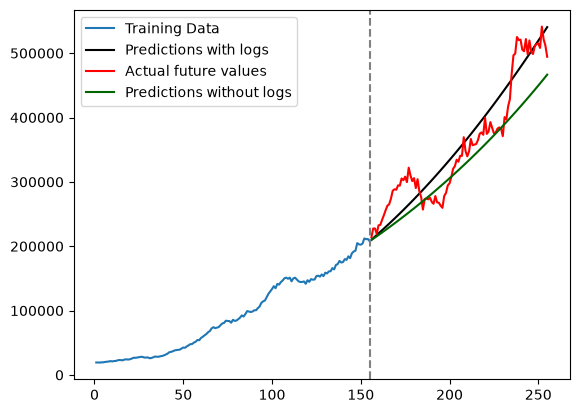

In [36]:
plt.plot(tme_train, y_train, label = 'Training Data')
plt.plot(tme_test, np.exp(fcast_mean), label = 'Predictions with logs', color = 'black') #Note the exponentiation
plt.plot(tme_test, y_test, color = 'red',  label = 'Actual future values')
plt.plot(tme_test, preds_nolog, color = 'darkgreen',  label = 'Predictions without logs')
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.legend()
plt.show()

In [37]:
fcast_se = fcast.se_mean
alpha = 0.05
z_alpha_half = stats.norm.ppf(1 - alpha/2)
predlower = fcast_mean - z_alpha_half * fcast_se
predupper = fcast_mean + z_alpha_half * fcast_se
fcast_int = fcast.conf_int()
print(np.column_stack([predlower, predupper, fcast_int]))

[[12.21053987 12.30100338 12.21053987 12.30100338]
 [12.2033213  12.33101686 12.2033213  12.33101686]
 [12.20047263 12.35657513 12.20047263 12.35657513]
 [12.19987842 12.37979397 12.19987842 12.37979397]
 [12.20071763 12.40149472 12.20071763 12.40149472]
 [12.20256838 12.42209958 12.20256838 12.42209958]
 [12.20517962 12.44185993 12.20517962 12.44185993]
 [12.20838747 12.46093995 12.20838747 12.46093995]
 [12.21207794 12.47945394 12.21207794 12.47945394]
 [12.21616788 12.49748536 12.21616788 12.49748536]
 [12.22059445 12.51509739 12.22059445 12.51509739]
 [12.22530874 12.53233922 12.22530874 12.53233922]
 [12.2302718  12.54925011 12.2302718  12.54925011]
 [12.23545204 12.56586197 12.23545204 12.56586197]
 [12.24082335 12.58220121 12.24082335 12.58220121]
 [12.24636393 12.59828994 12.24636393 12.59828994]
 [12.2520553  12.61414694 12.2520553  12.61414694]
 [12.25788165 12.62978832 12.25788165 12.62978832]
 [12.26382933 12.64522804 12.26382933 12.64522804]
 [12.26988646 12.66047827 12.26

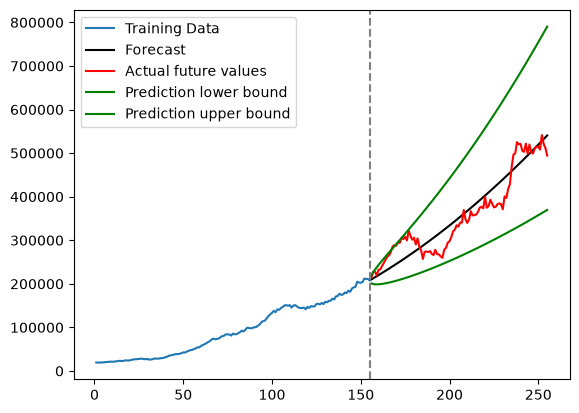

In [38]:
plt.plot(tme_train, y_train, label = 'Training Data')
plt.plot(tme_test, np.exp(fcast_mean), label = 'Forecast', color = 'black') #Note the exponentiation
plt.plot(tme_test, y_test, color = 'red',  label = 'Actual future values')
plt.plot(tme_test, np.exp(predlower), color = 'green', label = 'Prediction lower bound')
plt.plot(tme_test, np.exp(predupper), color = 'green', label = 'Prediction upper bound')
plt.axvline(x=n_train, color='gray', linestyle='--')
plt.legend()
plt.show()

### Residuals: raw data versus logarithms

From the residual plots below, it is easy to see that the raw residuals grow more variable as house prices increase, while the log residuals have a much more stable spread. This supports roughly constant percentage errors rather than constant dollar errors. Compare how the spread changes over time, not the numerical sizes of residuals on these different scales.

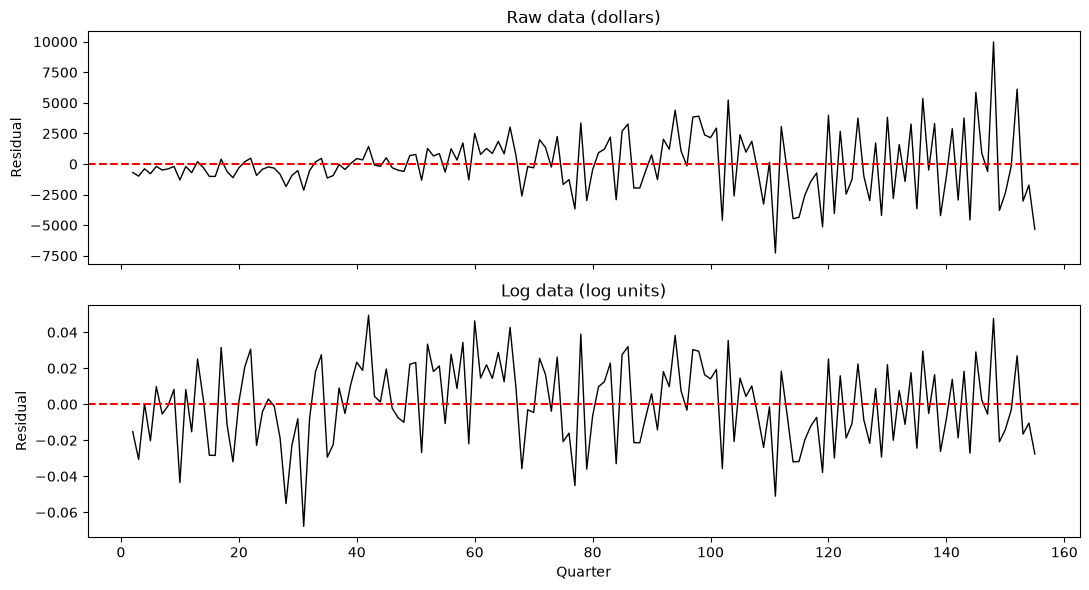

In [39]:
resid_raw = AutoReg(y_train, lags=p).fit().resid
resid_log = armod_sm.resid

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, resid, label in zip(axes, [resid_raw, resid_log],
                           ['Raw data (dollars)', 'Log data (log units)']):
    ax.plot(tme_train[p:], resid, color='black', linewidth=1)
    ax.axhline(0, color='red', linestyle='--')
    ax.set(title=label, ylabel='Residual')
axes[-1].set_xlabel('Quarter')
plt.tight_layout()
plt.show()

## Residuals and AutoCorrelation

Given a set of values $\epsilon_1, \dots, \epsilon_n$, how do we determine if $\epsilon_t \overset{\text{i.i.d}}{\sim} N(0, \sigma^2)$ is a good model for the data? Here are three example datasets. 

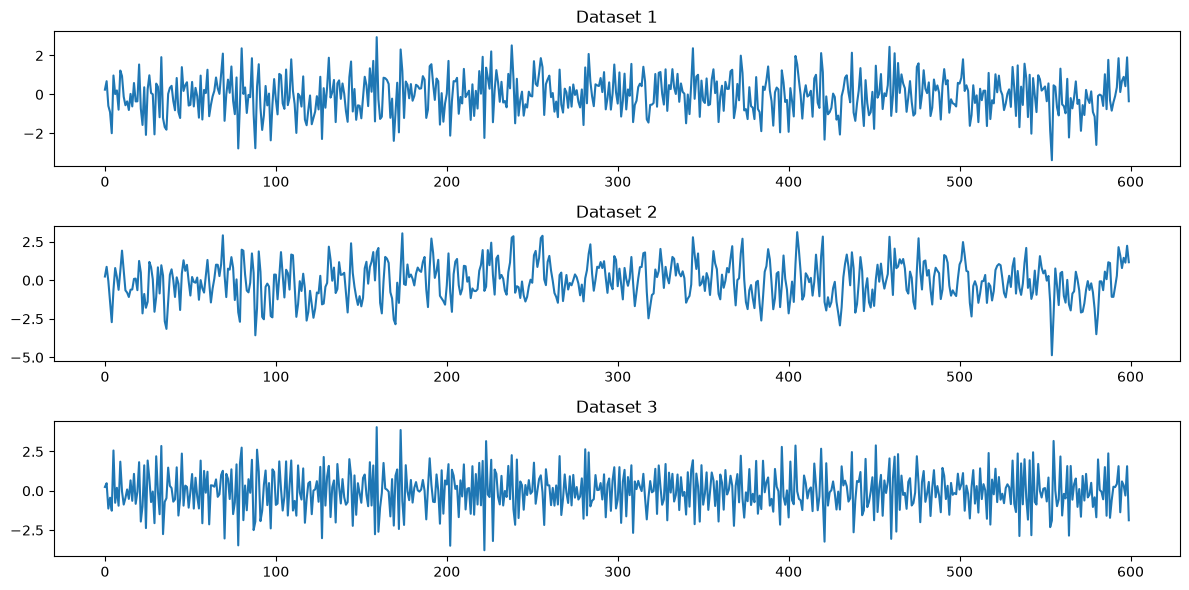

In [40]:
n = 600
seed = 43
rng = np.random.default_rng(seed)
sig = 1
y_wn = rng.normal(loc = 0, scale = sig, size = n)
y_0 = np.concatenate(([0], y_wn))

fig, axes = plt.subplots(nrows = 3, ncols = 1, figsize = (12, 6))


axes[0].plot(y_wn)
axes[0].set_title('Dataset 1')

theta = 0.8
y_ma_1 = y_0[1:] + theta * y_0[:-1]
axes[1].plot(y_ma_1)
axes[1].set_title(f'Dataset 2')

theta = -0.8
y_ma_2 = y_0[1:] + theta * y_0[:-1] #y_ma_2 is simulated data from MA(1) with negative theta
axes[2].plot(y_ma_2)
axes[2].set_title(f'Dataset 3')

plt.tight_layout()
plt.show()

We can distinguish between these datasets by computing the sample ACF which is defined as follows. Given a time series dataset $y_1, \dots, y_n$ and a **lag** h, define
\begin{equation}
   r_h := \frac{\sum_{t=1}^{n-h} (y_t - \bar{y})(y_{t+h} - \bar{y})}{\sum_{t=1}^n (y_t - \bar{y})^2}
\end{equation}
for $h = 0, 1, 2, \dots$. Here $\bar{y}$ is simply the mean of $z_1, \dots, z_n$. The acf plot graphs $h$ on the x-axis and $r_h$ on the y-axis. The quantity $r_h$ is known as the **sample autocorrelation** of the data at lag $h$ (acf stands for "Autocorrelation Function").

Below we compute the sample ACF. 

In [41]:
def sample_acf(y, h_max):
    n = len(y)
    y_mean = sum(y) / n
    denominator = sum((y_t - y_mean) ** 2 for y_t in y)
    autocorr = []

    for h in range(h_max + 1):
        numerator = sum((y[t] - y_mean) * (y[t + h] - y_mean) for t in range(n - h))
        r_h = numerator / denominator
        autocorr.append(r_h)

    return autocorr

The sample ACF for each of the three datasets is plotted below. 

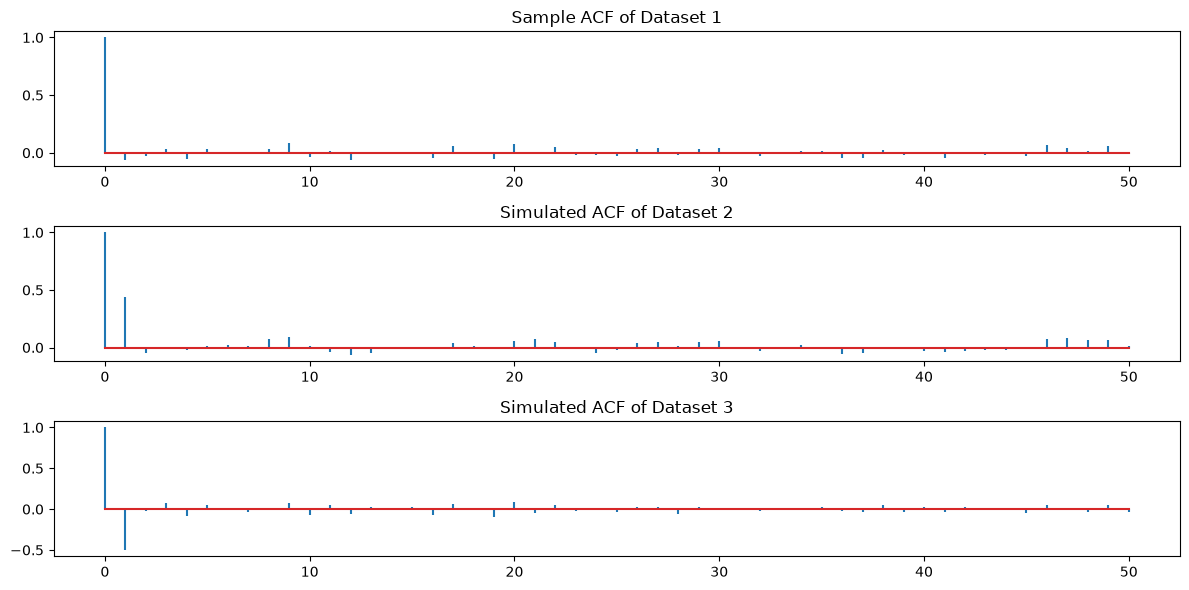

In [42]:
fig, axes = plt.subplots(nrows = 3, ncols = 1, figsize = (12, 6))
h_max = 50

sample_acf_vals_wn = sample_acf(y_wn, h_max)
markerline, stemline, baseline = axes[0].stem(range(0, h_max + 1), sample_acf_vals_wn)
markerline.set_marker("None")
axes[0].set_title('Sample ACF of Dataset 1')

sample_acf_vals_ma_1 = sample_acf(y_ma_1, h_max)
markerline, stemline, baseline = axes[1].stem(range(0, h_max + 1), sample_acf_vals_ma_1)
markerline.set_marker("None")
theta = 0.8
axes[1].set_title(f'Simulated ACF of Dataset 2')

sample_acf_vals_ma_2 = sample_acf(y_ma_2, h_max)
markerline, stemline, baseline = axes[2].stem(range(0, h_max + 1), sample_acf_vals_ma_2)
markerline.set_marker("None")
theta = -0.8
axes[2].set_title(f'Simulated ACF of Dataset 3')

plt.tight_layout()
plt.show()

Note that the autocorrelation at lag 0 is always one. For the first dataset, all the other autocorrelations are negligible which suggests that this dataset is i.i.d N(0, $\sigma^2$) (i.e., it is Gaussian white noise). For the other two datasets, the autocorrelation at lag 1 is nonnegligible. Therefore, the second and third datasets are not i.i.d $N(0, \sigma^2)$. 

There is an inbuilt function in statsmodels for plotting the sample_acf (and another inbuilt function for plotting the sample_acf). Its use is demonstrated below. Let us check that it gives identical answers to our computation.  

In [43]:
from statsmodels.tsa.stattools import acf

acf_values_wn = acf(y_wn, nlags=h_max)
print(np.column_stack([sample_acf_vals_wn, acf_values_wn]))

[[ 1.00000000e+00  1.00000000e+00]
 [-6.18986853e-02 -6.18986853e-02]
 [-3.16190776e-02 -3.16190776e-02]
 [ 3.37684035e-02  3.37684035e-02]
 [-5.08194511e-02 -5.08194511e-02]
 [ 3.25331941e-02  3.25331941e-02]
 [ 8.74858962e-03  8.74858962e-03]
 [-1.16498128e-02 -1.16498128e-02]
 [ 3.26472220e-02  3.26472220e-02]
 [ 8.33178480e-02  8.33178480e-02]
 [-3.27430872e-02 -3.27430872e-02]
 [ 1.14743957e-02  1.14743957e-02]
 [-6.46748355e-02 -6.46748355e-02]
 [-9.26355222e-03 -9.26355222e-03]
 [-1.48030902e-03 -1.48030902e-03]
 [ 5.98188096e-03  5.98188096e-03]
 [-4.20248527e-02 -4.20248527e-02]
 [ 5.47736551e-02  5.47736551e-02]
 [ 9.57612253e-03  9.57612253e-03]
 [-5.55307936e-02 -5.55307936e-02]
 [ 7.32655261e-02  7.32655261e-02]
 [ 8.66336997e-03  8.66336997e-03]
 [ 5.21590566e-02  5.21590566e-02]
 [-1.51121264e-02 -1.51121264e-02]
 [-2.06604710e-02 -2.06604710e-02]
 [-2.69178655e-02 -2.69178655e-02]
 [ 3.49261541e-02  3.49261541e-02]
 [ 3.86381603e-02  3.86381603e-02]
 [-2.07370593e-02 -2

The following function plots the sample_acf values. 

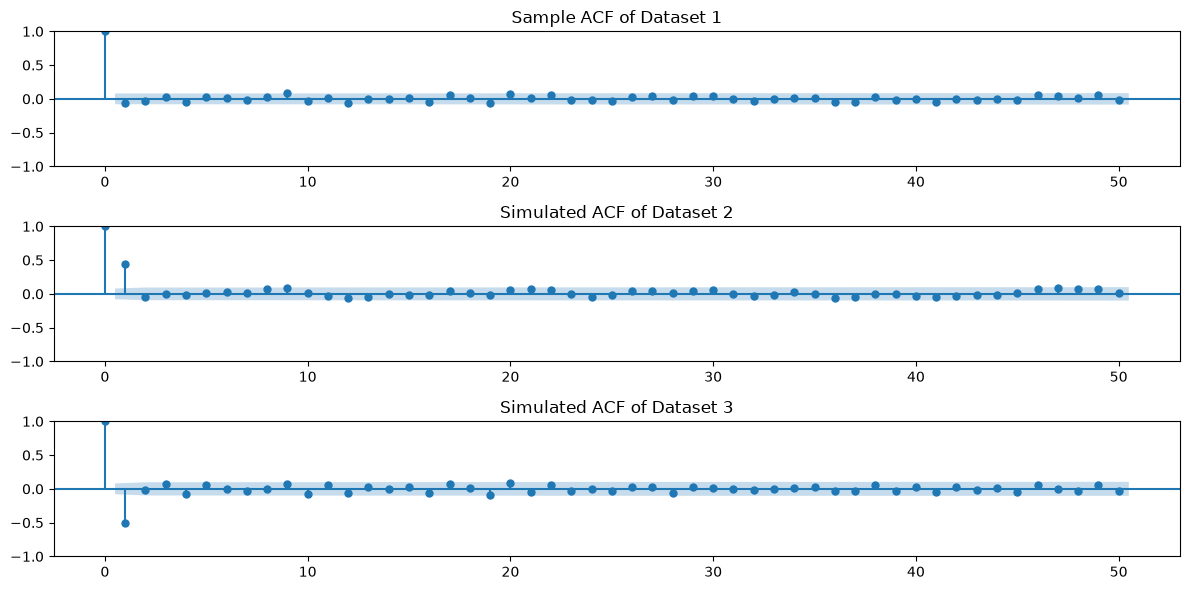

In [44]:
from statsmodels.graphics.tsaplots import plot_acf
fig, axes = plt.subplots(nrows = 3, ncols = 1, figsize = (12, 6))

plot_acf(y_wn, lags = h_max, ax = axes[0])
axes[0].set_title('Sample ACF of Dataset 1')

plot_acf(y_ma_1, lags = h_max, ax = axes[1])
theta = 0.8
axes[1].set_title(f'Simulated ACF of Dataset 2')

plot_acf(y_ma_2, lags = h_max, ax = axes[2])
theta = -0.8
axes[2].set_title(f'Simulated ACF of Dataset 3')

plt.tight_layout()
plt.show()

The plot_acf function gives a blue shading to assess whether each autocorrelation is non-negligible (significant) or not. Values appearing inside the blue area or just outside of it can be ignored. 

Let us go back to the GDP dataset. 

  observation_date      GDP
0       1947-01-01  243.164
1       1947-04-01  245.968
2       1947-07-01  249.585
3       1947-10-01  259.745
4       1948-01-01  265.742


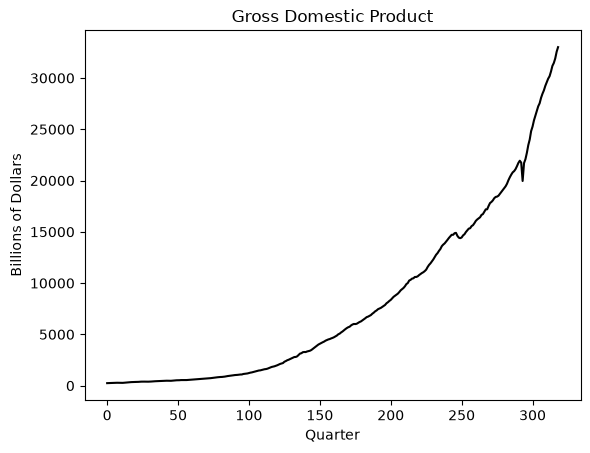

In [45]:
gdp = pd.read_csv("GDP_29Oct2026.csv")
print(gdp.head())
y = gdp['GDP'].to_numpy()
plt.plot(y, color = 'black')
plt.xlabel('Quarter')
plt.ylabel('Billions of Dollars')
plt.title('Gross Domestic Product')
plt.show()

In [46]:
n = len(y)
tme = range(1, n+1)
n_test = 50
#n_test = 12 
n_train = n - n_test
y_train = y[:n_train]
tme_train = tme[:n_train]
y_test = y[n_train:]
tme_test = tme[n_train:]

In [47]:
ylog_train = np.log(y_train)
ylog_test = np.log(y_test)

We fit AR(1) to log-GDP. 

In [48]:
from statsmodels.tsa.ar_model import AutoReg
armod_sm = AutoReg(ylog_train, lags = p).fit()
print(armod_sm.summary())

                            AutoReg Model Results                             
Dep. Variable:                      y   No. Observations:                  269
Model:                     AutoReg(1)   Log Likelihood                 830.433
Method:               Conditional MLE   S.D. of innovations              0.011
Date:                Fri, 30 Oct 2026   AIC                          -1654.866
Time:                        22:18:16   BIC                          -1644.093
Sample:                             1   HQIC                         -1650.539
                                  269                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0283      0.004      7.232      0.000       0.021       0.036
y.L1           0.9984      0.000   2014.926      0.000       0.997       0.999
                                    Roots           

To check whether this is a good model, we can plot the residuals. 

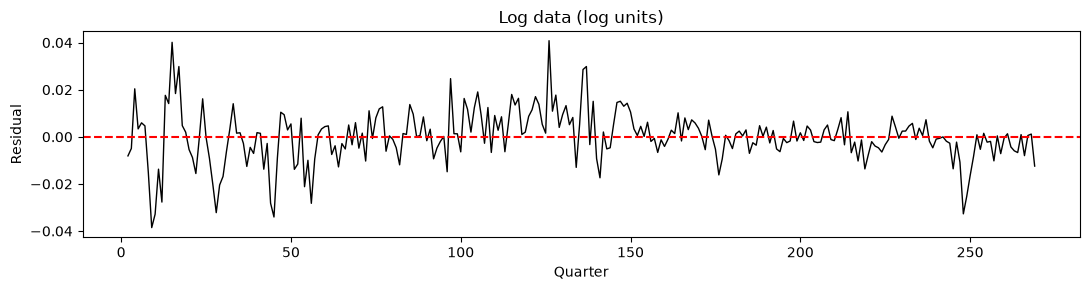

In [49]:
resid_log = armod_sm.resid

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(tme_train[p:], resid_log, color='black', linewidth=1)
ax.axhline(0, color='red', linestyle='--')
ax.set(title='Log data (log units)', xlabel='Quarter', ylabel='Residual')
plt.tight_layout()
plt.show()

To assess whether the i.i.d $N(0, \sigma^2)$ assumption for the autoregression errors is justifiable, let us compute the sample acf of the residuals. 

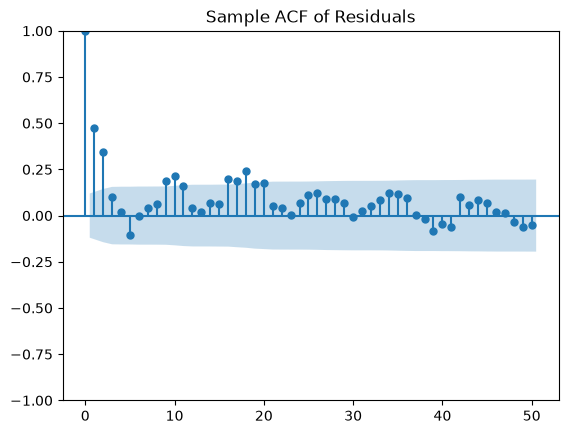

In [50]:
h_max = 50
fig, ax = plt.subplots() 
plot_acf(resid_log, lags = h_max, ax = ax)
ax.set_title("Sample ACF of Residuals")
plt.show()

There are two non-negligible autocorrelations at lags 1 and 2. This suggests that i.i.d $N(0, \sigma^2)$ is not a good model for the residuals here. The Moving Average (MA) model of order 2 is more suitable for the residuals. We shall apply this model in the next lecture. 